In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:

file_path='/content/study_hours_exam_score_300.csv'
if not os.path.exists(file_path):
    from google.colab import files
    uploaded=files.upload()
    file_path=next(iter(uploaded))
df=pd.read_csv(file_path)
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])
display(df.head())

Rows: 300
Columns: 2


,Study_Hours_per_Day,Exam_Score
0,5.68,83.81
1,9.96,98.25
2,9.09,94.43
3,10.55,83.94
4,5.22,62.91


In [ ]:
data=df[['Study_Hours_per_Day','Exam_Score']].copy()
data['Study_Hours_per_Day']=pd.to_numeric(data['Study_Hours_per_Day'],errors='coerce')
data['Exam_Score']=pd.to_numeric(data['Exam_Score'],errors='coerce')
invalid_study_hours=int((data['Study_Hours_per_Day']<0).sum())
data.loc[data['Study_Hours_per_Day']<0,'Study_Hours_per_Day']=np.nan
data=data.dropna().reset_index(drop=True)
print("Rows before cleaning:",len(df))
print("Invalid/missing study hours values:",invalid_study_hours)
print("Rows removed:",len(df)-len(data))
print("Rows after cleaning:",len(data))
display(data.head(10))

Rows before cleaning: 300
Invalid/missing study hours values: 1
Rows removed: 5
Rows after cleaning: 295


,Study_Hours_per_Day,Exam_Score
0,5.68,83.81
1,9.96,98.25
2,9.09,94.43
3,10.55,83.94
4,5.22,62.91
5,11.77,96.03
6,10.83,91.93
7,3.31,73.03
8,9.16,91.41
9,8.29,89.91


In [ ]:
X=data[['Study_Hours_per_Day']]
y=data['Exam_Score']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)
print("Training samples:",len(X_train))
print("Testing samples:",len(X_test))

Training samples: 236
Testing samples: 59


In [ ]:
model=LinearRegression()
model.fit(X_train,y_train)
sk_b=model.intercept_
sk_w=model.coef_[0]
y_pred=model.predict(X_test)
print(f"Intercept: {sk_b:.6f}")
print(f"Slope: {sk_w:.6f}")
print(f"Regression Equation: Exam Score = {sk_b:.2f} + ({sk_w:.2f} × Study Hours)")

Intercept: 50.125917
Slope: 4.314033
Regression Equation: Exam Score = 50.13 + (4.31 × Study Hours)


In [ ]:
def gradient_descent(X,y,learning_rate=0.01,epochs=5000):
    x=np.asarray(X,dtype=float).reshape(-1)
    target=np.asarray(y,dtype=float).reshape(-1)
    n=len(x)
    w=0.0
    b=0.0
    history=[]
    for _ in range(epochs):
        pred=w*x+b
        error=pred-target
        history.append(np.mean(error**2))
        dw=(2/n)*np.sum(x*error)
        db=(2/n)*np.sum(error)
        w-=learning_rate*dw
        b-=learning_rate*db
    return w,b,np.array(history)

In [ ]:
gd_w,gd_b,loss_history=gradient_descent(X_train['Study_Hours_per_Day'],y_train,0.01,5000)
gd_pred=gd_w*X_test['Study_Hours_per_Day'].to_numpy()+gd_b
print(f"Learning rate: 0.01")
print(f"Epochs: 5000")
print(f"Intercept: {gd_b:.6f}")
print(f"Slope: {gd_w:.6f}")
print(f"Final training MSE: {loss_history[-1]:.6f}")

Learning rate: 0.01
Epochs: 5000
Intercept: 50.125916
Slope: 4.314033
Final training MSE: 46.538410


In [ ]:
metrics=pd.DataFrame({'MAE':[mean_absolute_error(y_test,y_pred),
                             mean_absolute_error(y_test,gd_pred)],
                      'MSE':[mean_squared_error(y_test,y_pred),
                             mean_squared_error(y_test,gd_pred)],
                      'RMSE':[np.sqrt(mean_squared_error(y_test,y_pred))
                           ,np.sqrt(mean_squared_error(y_test,gd_pred))],
                      'R2':[r2_score(y_test,y_pred),r2_score(y_test,gd_pred)]},
                          index=['Linear Regression','Gradient Descent'])
display(metrics.round(4))

,MAE,MSE,RMSE,R2
Linear Regression,5.1054,43.0898,6.5643,0.8517
Gradient Descent,5.1054,43.0897,6.5643,0.8517


In [ ]:
predictions=pd.DataFrame({'Study Hours':X_test['Study_Hours_per_Day'].to_numpy(),
                          'Actual Exam Score':y_test.to_numpy(),'Linear Regression':y_pred.round(2),
                          'Gradient Descent':gd_pred.round(2)}).sort_values('Study Hours')
display(predictions)

,Study Hours,Actual Exam Score,Linear Regression,Gradient Descent
6,1.15,45.96,55.09,55.09
32,1.26,58.83,55.56,55.56
10,1.32,45.55,55.82,55.82
50,1.39,51.11,56.12,56.12
37,1.66,58.19,57.29,57.29
27,2.17,50.43,59.49,59.49
19,2.23,56.43,59.75,59.75
30,2.53,57.26,61.04,61.04
53,2.79,58.99,62.16,62.16
33,2.87,55.17,62.51,62.51


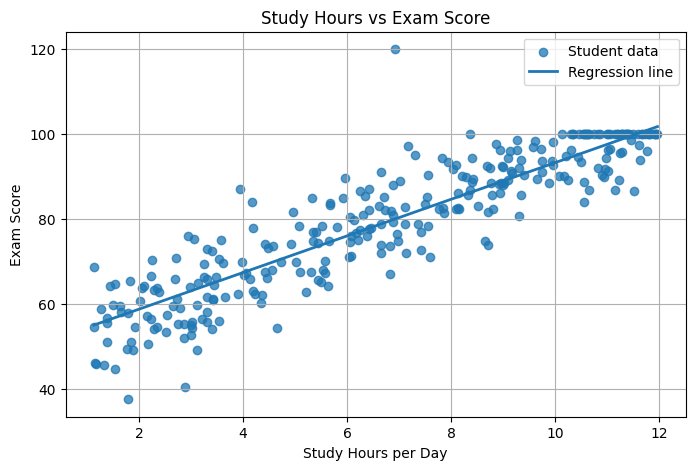

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(data['Study_Hours_per_Day'],data['Exam_Score'],alpha=0.75,label='Student data')
x_line=np.linspace(data['Study_Hours_per_Day'].min(),data['Study_Hours_per_Day'].max(),200)
plt.plot(x_line,sk_b+sk_w*x_line,linewidth=2,label='Regression line')
plt.xlabel('Study Hours per Day')
plt.ylabel('Exam Score')
plt.title('Study Hours vs Exam Score')
plt.legend()
plt.grid(True)
plt.show()

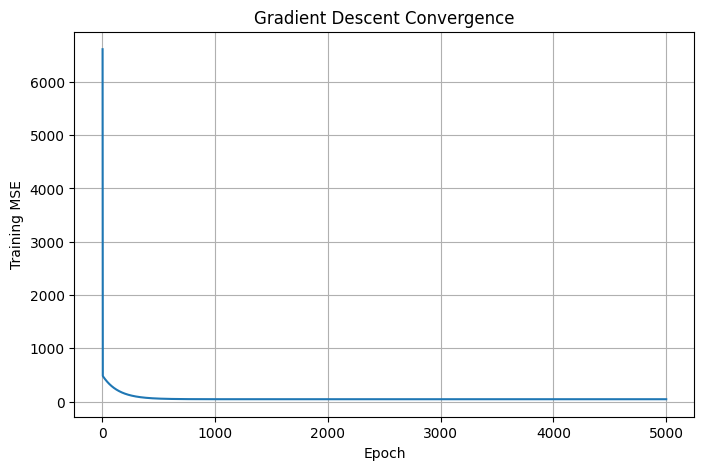

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(np.arange(1,len(loss_history)+1),loss_history)
plt.xlabel('Epoch')
plt.ylabel('Training MSE')
plt.title('Gradient Descent Convergence')
plt.grid(True)
plt.show()

In [ ]:
learning_rates=[0.001,0.005,0.01]
lr_results=[]
for rate in learning_rates:
    w,b,history=gradient_descent(X_train['Study_Hours_per_Day'],y_train,rate,5000)
    lr_results.append([rate,5000,w,b,history[-1]])
lr_results=pd.DataFrame(lr_results,columns=['Learning Rate','Epochs','Slope','Intercept','Final Train MSE'])
display(lr_results.round(6))

,Learning Rate,Epochs,Slope,Intercept,Final Train MSE
0,0.001,5000,5.258040,42.192781,58.155523
1,0.005,5000,4.314681,50.120467,46.538415
2,0.010,5000,4.314033,50.125916,46.538410


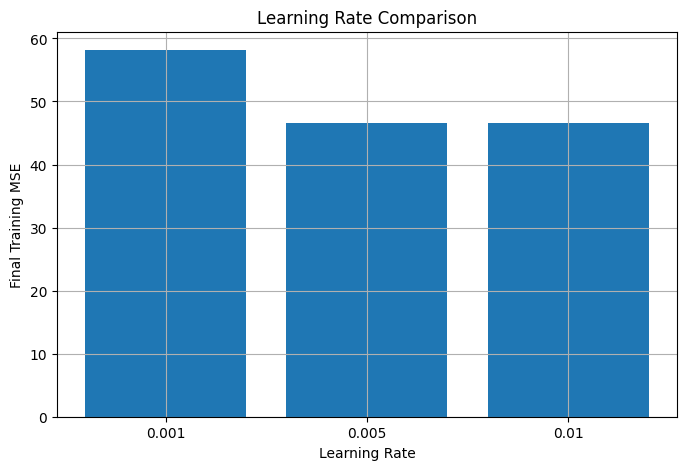

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(lr_results['Learning Rate'].astype(str),lr_results['Final Train MSE'])
plt.xlabel('Learning Rate')
plt.ylabel('Final Training MSE')
plt.title('Learning Rate Comparison')
plt.grid(True)
plt.show()

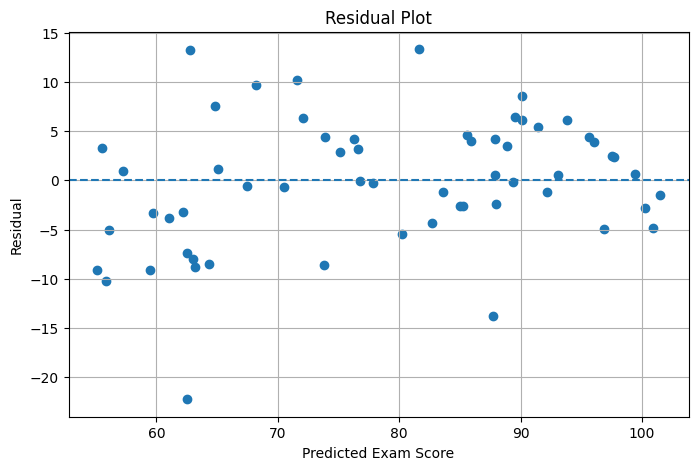

In [ ]:
residuals=y_test.to_numpy()-y_pred
plt.figure(figsize=(8,5))
plt.scatter(y_pred,residuals)
plt.axhline(0,linestyle='--')
plt.xlabel('Predicted Exam Score')
plt.ylabel('Residual')
plt.title('Residual Plot')
plt.grid(True)
plt.show()

In [ ]:
new_data=pd.DataFrame({'Study_Hours_per_Day':[8]})
prediction=model.predict(new_data)[0]
print(f"Predicted exam score for 8 hours of study: {prediction:.2f}")
print("Parameters close:",np.isclose(sk_w,gd_w,atol=0.001) and np.isclose(sk_b,gd_b,atol=0.001))

Predicted exam score for 8 hours of study: 84.64
Parameters close: True


In [ ]:
print("Linear Regression and Gradient Descent converge to nearly identical parameters and produce matching test metrics for this experiment.")
display(metrics.round(4))

Linear Regression and Gradient Descent converge to nearly identical parameters and produce matching test metrics for this experiment.


,MAE,MSE,RMSE,R2
Linear Regression,5.1054,43.0898,6.5643,0.8517
Gradient Descent,5.1054,43.0897,6.5643,0.8517


In [ ]:
print(f"Regression equation: Exam Score = {sk_b:.2f} + ({sk_w:.2f} x Study Hours). Test R2 = {r2_score(y_test,y_pred):.4f}. Prediction for 8 hours study = {prediction:.2f} exam score.")

Regression equation: Exam Score = 50.13 + (4.31 x Study Hours). Test R2 = 0.8517. Prediction for 8 hours study = 84.64 exam score.
